In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression

K = 3  Inertia = 283.6007
K = 2  Inertia = 2752.9291
K = 4  Inertia = 242.8477


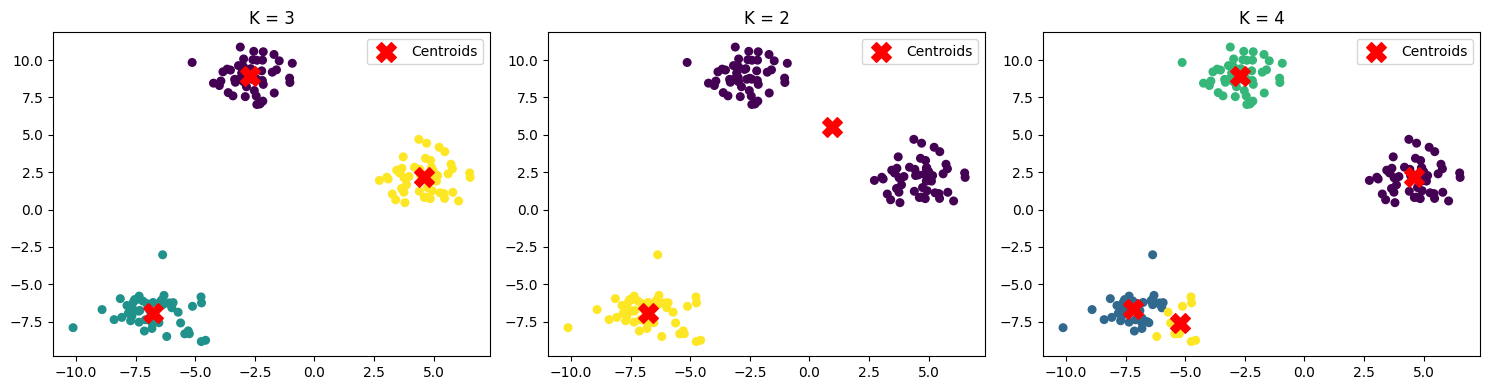

In [2]:
# Task 1: K-Means on make_blobs with K = 3, 2, 4
X, _ = make_blobs(n_samples=150, n_features=2, centers=3, random_state=42)
inertias = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [3, 2, 4]):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias[k] = km.inertia_
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=30)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker="X", s=200, c="red", label="Centroids")
    ax.set_title(f"K = {k}")
    ax.legend()
    print(f"K = {k}  Inertia = {km.inertia_:.4f}")
plt.tight_layout()
plt.show()
# Inertia always decreases as K grows (K = n gives 0), so the lowest inertia is not the best K.
# The best K is where the drop flattens (elbow) or where silhouette score peaks.

In [3]:
# Task 2: Random initialization vs K-Means++
kmeans_random = KMeans(n_clusters=3, init="random", n_init=10, random_state=42)
kmeans_plus = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
kmeans_random.fit(X)
kmeans_plus.fit(X)
print("Random Inertia:", kmeans_random.inertia_)
print("K-Means++ Inertia:", kmeans_plus.inertia_)

Random Inertia: 283.60067487251115
K-Means++ Inertia: 283.60067487251115


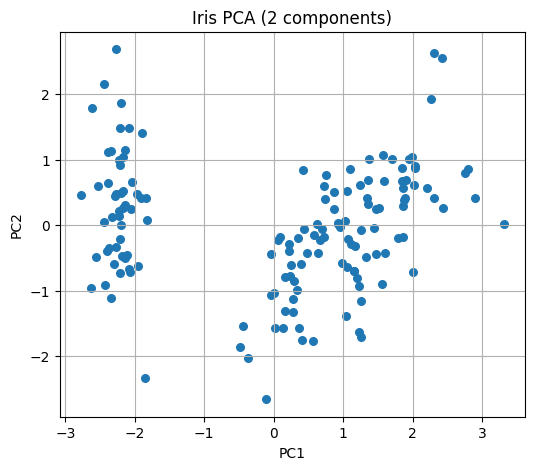

Explained variance ratio: [0.72962445 0.22850762]
PC1: 0.7296 PC2: 0.2285
Sum: 0.9581
Retains at least 90%: True


In [4]:
# Task 3: PCA on Iris (features only)
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
pca_iris = PCA(n_components=2)
pcs = pca_iris.fit_transform(X_iris)
plt.figure(figsize=(6, 5))
plt.scatter(pcs[:, 0], pcs[:, 1], s=30)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Iris PCA (2 components)")
plt.grid(True)
plt.show()
ratios = pca_iris.explained_variance_ratio_
print("Explained variance ratio:", ratios)
print("PC1:", round(ratios[0], 4), "PC2:", round(ratios[1], 4))
print("Sum:", round(ratios.sum(), 4))
print("Retains at least 90%:", ratios.sum() >= 0.90)

eps = 0.3: clusters = 2, noise points = 0
eps = 0.15: clusters = 16, noise points = 26
eps = 0.5: clusters = 2, noise points = 0


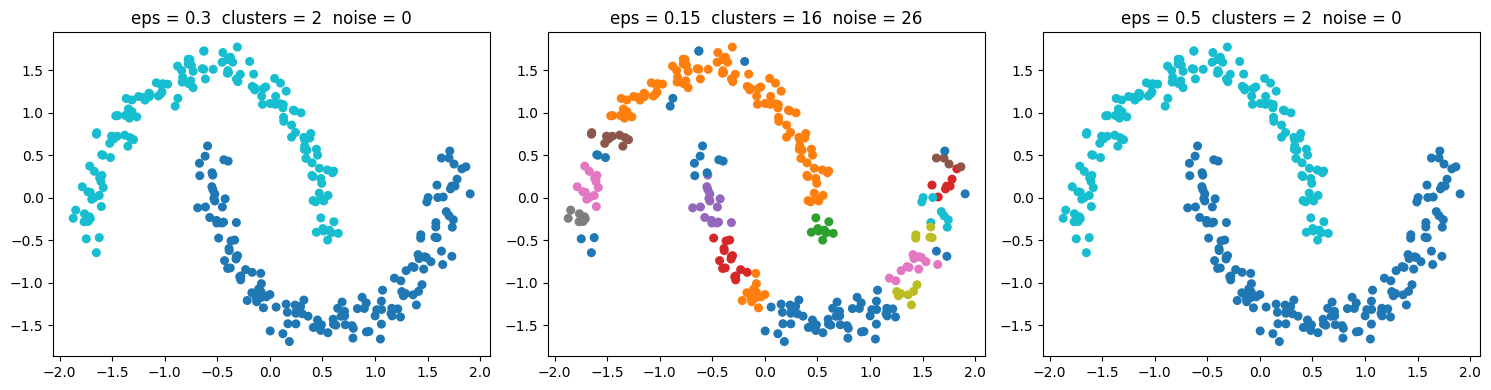

In [5]:
# Task 4: DBSCAN on make_moons
X_m, _ = make_moons(n_samples=300, noise=0.06, random_state=42)
X_m = StandardScaler().fit_transform(X_m)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, eps in zip(axes, [0.3, 0.15, 0.5]):
    db = DBSCAN(eps=eps, min_samples=5)
    lab = db.fit_predict(X_m)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise = int(np.sum(lab == -1))
    ax.scatter(X_m[:, 0], X_m[:, 1], c=lab, cmap="tab10", s=30)
    ax.set_title(f"eps = {eps}  clusters = {n_clusters}  noise = {n_noise}")
    print(f"eps = {eps}: clusters = {n_clusters}, noise points = {n_noise}")
plt.tight_layout()
plt.show()
# Small eps splits the moons into many small clusters plus noise; large eps merges them.

Original shape: (300, 2) Polynomial shape: (300, 9) PCA shape: (300, 3)
Explained variance ratio: [0.43227168 0.27899856 0.13406165] Sum: 0.8453318820566535


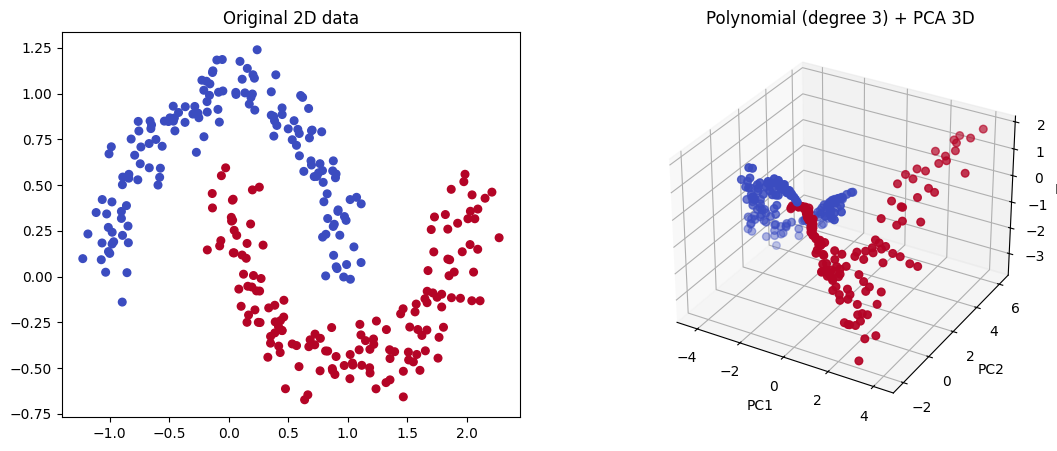

Linear classifier accuracy on original 2D: 0.8633
Linear classifier accuracy on 3D PCA space: 0.88


In [6]:
# Task 5: Polynomial features + PCA (3D) on non-linearly separable data
X_p, y_p = make_moons(n_samples=300, noise=0.1, random_state=42)
poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X_p)
X_poly_s = StandardScaler().fit_transform(X_poly)
pca3 = PCA(n_components=3)
X_3d = pca3.fit_transform(X_poly_s)
print("Original shape:", X_p.shape, "Polynomial shape:", X_poly.shape, "PCA shape:", X_3d.shape)
print("Explained variance ratio:", pca3.explained_variance_ratio_, "Sum:", pca3.explained_variance_ratio_.sum())

fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(X_p[:, 0], X_p[:, 1], c=y_p, cmap="coolwarm", s=30)
ax1.set_title("Original 2D data")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=y_p, cmap="coolwarm", s=30)
ax2.set_title("Polynomial (degree 3) + PCA 3D")
ax2.set_xlabel("PC1"); ax2.set_ylabel("PC2"); ax2.set_zlabel("PC3")
plt.show()

acc_orig = LogisticRegression().fit(X_p, y_p).score(X_p, y_p)
acc_3d = LogisticRegression().fit(X_3d, y_p).score(X_3d, y_p)
print("Linear classifier accuracy on original 2D:", round(acc_orig, 4))
print("Linear classifier accuracy on 3D PCA space:", round(acc_3d, 4))
# Higher linear accuracy in the transformed space means the classes became (more) linearly separable.